2023 (258 mornings): reported P&L RMS USD 517,683, mean +23,127
  prediction                          mean unexplained  RMS unexplained
  ladder x curve move, no carry                +62,056           74,011
  carry + ladder x curve move                     +839           16,615
  full revaluation (our system)                    +13           16,161
  carry alone: mean USD +61,217 a day, between +30,749 and +172,265
  split of the unexplained: P&L system vs our full revaluation (DATA) RMS 16,161; full revaluation vs carry + ladder (MODEL) RMS 3,128

Noise model fitted on 2023: the two systems' curves differ by s = 0.0963bp per vertex a day
  sd of U / noise_sd: 2023 1.000, 2024 Q1 1.124
  expected noise sd: 2023 average USD 16,494; after the 2024-08-21 curve trade USD 26,543

Red mornings in 2024 (|unexplained| over 3.5 sd): fixed USD 58,079 from 2023 -> 49; scaled by today's noise_sd -> 34; fixed but not scaled: 15, scaled but not fixed: 0
  red mornings by month of 2024:  01: 0/0  02

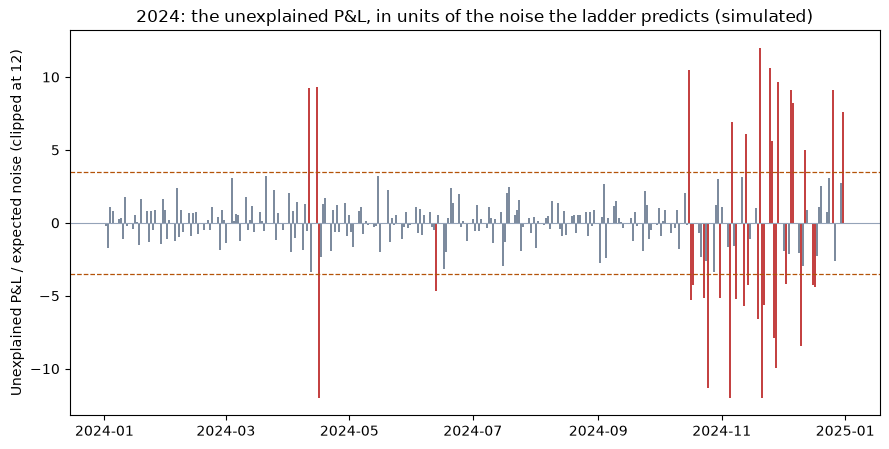

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    r'C:\Users\franklinpeng\Desktop\RDA Risk test\DataSource\rates_desk_feed.csv',
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100


def carry(Q, V, VA, CASH):
    """TODO: The walk's time step for VALUE, every morning (USD): yesterday's positions one day older on yesterday's
    curve, plus the cash they paid out (coupons, principal), minus yesterday's value.
    Qp = Q shifted down a row (row 0 is its own yesterday), Vp likewise; carry = sum over bonds of Qp x (VA + CASH - Vp)."""
    Qp = np.vstack([Q[:1], Q[:-1]])
    Vp = np.vstack([V[:1], V[:-1]])

    return np.sum(
        Qp * (VA + CASH - Vp),
        axis=1
    )



def predicted_pnl(carry_, L_prev, moves):
    """TODO: The risk-based P&L every morning: carry + what yesterday's ladder says the curve move made,
    -sum(L_prev x moves) over the 11 vertices (moves in bp, L_prev in USD per bp)."""
    return carry_ - np.sum(L_prev * moves, axis=1)

def noise_sd(L_prev, s):
    """TODO: The unexplained P&L to expect from mark differences ALONE (USD): if the P&L system's curve differs from the
    feed by independent noise of s bp at each vertex each day, a day's move differs by sqrt(2) s, so the gap has
    sd sqrt(2) x s x sqrt(sum of L_prev squared)."""
    return (
        np.sqrt(2)
        * s
        * np.sqrt(np.sum(L_prev ** 2, axis=1))
    )


# ---------------------------------------------------------------------------
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, 11)), np.diff(Z, axis=0) * 100])
Qp = np.vstack([Q[:1], Q[:-1]])
L_prev = np.einsum('nb,nbk->nk', Qp, np.vstack([H['K'][:1], H['K'][:-1]]))    # yesterday's report ladder
checks = [('carry', lambda: carry(Q[:3], H['V'][:3], H['VA'][:3], H['CASH'][:3])),
          ('predicted_pnl', lambda: predicted_pnl(np.zeros(3), np.ones((3, 11)), np.ones((3, 11)))),
          ('noise_sd', lambda: noise_sd(np.ones((3, 11)), 0.1))]
todo = next((name for name, f in checks if f() is None), None)
if todo:
    print(f"Fill in the TODOs above, then run again. Next: {todo}()")
else:
    c = carry(Q, H['V'], H['VA'], H['CASH'])
    full = c + (Qp * (H['V'] - H['VA'])).sum(1)          # our full revaluation: time step + market step
    pred = predicted_pnl(c, L_prev, moves)
    U = PNL - pred                                        # the unexplained P&L the morning page shows
    rms = lambda x: float(np.sqrt(np.mean(x ** 2)))
    y23 = REP[DATES[REP].year == 2023]
    y24 = REP[DATES[REP].year == 2024]
    print(f"2023 ({len(y23)} mornings): reported P&L RMS USD {rms(PNL[y23]):,.0f}, mean {PNL[y23].mean():+,.0f}")
    print(f"  {'prediction':<34}{'mean unexplained':>18}{'RMS unexplained':>17}")
    for lbl, p in (('ladder x curve move, no carry', pred - c), ('carry + ladder x curve move', pred),
                   ('full revaluation (our system)', full)):
        print(f"  {lbl:<34}{(PNL - p)[y23].mean():>+18,.0f}{rms((PNL - p)[y23]):>17,.0f}")
    print(f"  carry alone: mean USD {c[y23].mean():+,.0f} a day, between {c[y23].min():+,.0f} and {c[y23].max():+,.0f}")
    print(f"  split of the unexplained: P&L system vs our full revaluation (DATA) RMS {rms((PNL - full)[y23]):,.0f};"
          f" full revaluation vs carry + ladder (MODEL) RMS {rms((full - pred)[y23]):,.0f}")

    g2 = np.sqrt((L_prev ** 2).sum(1))
    s = float(np.std(U[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
    z = U / noise_sd(L_prev, s)
    print(f"\nNoise model fitted on 2023: the two systems' curves differ by s = {s:.4f}bp per vertex a day")
    print(f"  sd of U / noise_sd: 2023 {np.std(z[y23]):.3f}, 2024 Q1 {np.std(z[y24[:62]]):.3f}")
    after = DATES[REP] >= '2024-08-22'
    print(f"  expected noise sd: 2023 average USD {noise_sd(L_prev, s)[y23].mean():,.0f}; after the 2024-08-21 curve "
          f"trade USD {noise_sd(L_prev, s)[REP][after].mean():,.0f}")

    fixed = 3.5 * np.std(U[y23])
    red_f = np.abs(U[y24]) > fixed
    red_s = np.abs(z[y24]) > 3.5
    print(f"\nRed mornings in 2024 (|unexplained| over 3.5 sd): fixed USD {fixed:,.0f} from 2023 -> {red_f.sum()}; "
          f"scaled by today's noise_sd -> {red_s.sum()}; fixed but not scaled: {(red_f & ~red_s).sum()}, "
          f"scaled but not fixed: {(red_s & ~red_f).sum()}")
    by = pd.DataFrame({'fixed': red_f, 'scaled': red_s}, index=DATES[y24]).groupby(DATES[y24].month).sum()
    print("  red mornings by month of 2024:  " + '  '.join(f"{m:02d}: {r.fixed}/{r.scaled}" for m, r in by.iterrows())
          + "   (fixed/scaled)")
    print(f"  largest |z|: {np.abs(z[y24]).max():.1f} on {DATES[y24][np.argmax(np.abs(z[y24]))].date()}")
    print(f"Mornings with |z| > 3.5 in 2023: {(np.abs(z[y23]) > 3.5).sum()} of {len(y23)}")

    fig, ax = plt.subplots(figsize=(9, 4.6))
    zz = np.clip(z[y24], -12, 12)
    ax.vlines(DATES[y24], 0, zz, color=np.where(np.abs(z[y24]) > 3.5, '#b91c1c', '#64748b'), lw=1.2)
    for h in (-3.5, 3.5):
        ax.axhline(h, color='#b45309', lw=0.9, ls='--')
    ax.axhline(0, color='#94a3b8', lw=0.8)
    ax.set_ylabel('Unexplained P&L / expected noise (clipped at 12)')
    ax.set_title('2024: the unexplained P&L, in units of the noise the ladder predicts (simulated)')
    plt.tight_layout()
    plt.show()
